In [1]:
#Import thu vien
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns

from pathlib import Path
import json
import textwrap
from scipy.stats import pearsonr, spearmanr, ttest_1samp, t, linregress
ROOT = Path.cwd()
OUT2 = ROOT / "outputs"/"output_02"
OUT = ROOT / "outputs"
FIG = OUT / "figures"

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
OUT2.mkdir(parents=True, exist_ok=True)
config = json.loads(
    (OUT / "config.json").read_text(encoding="utf-8")
)

STATES = config["states"]
CROPS = config["crops"]
SEASONS = config["seasons"]

df = pd.read_csv(
    OUT / "model_data_top12.csv",
    dtype={"Outlier_Flag": "boolean"}
)
dev = df[df["Crop_Year"] <= 2012].copy()

In [2]:
#Kiem tra tong quan du lieu
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nNumber of crops:", df["Crop"].nunique())
print("Year range:", df["Crop_Year"].min(), "-", df["Crop_Year"].max())
print("\nTop 12 crops:")
print(df["Crop"].value_counts())

Dataset shape: (111207, 10)

Columns:
['State_Name', 'District_Name', 'Crop_Year', 'Season', 'Crop', 'Area', 'Production', 'District_ID', 'Yield', 'Outlier_Flag']

Number of crops: 12
Year range: 1997 - 2015

Top 12 crops:
Crop
Rice                 15082
Maize                13787
Moong(Green Gram)    10106
Urad                  9710
Sesamum               8821
Groundnut             8770
Wheat                 7878
Sugarcane             7827
Rapeseed &Mustard     7533
Arhar/Tur             7476
Gram                  7227
Jowar                 6990
Name: count, dtype: int64


In [3]:
#Kiem tra missing va duplicate

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicated rows:", df.duplicated().sum())

Missing values:
State_Name          0
District_Name       0
Crop_Year           0
Season              0
Crop                0
Area                0
Production          0
District_ID         0
Yield               0
Outlier_Flag     1297
dtype: int64

Duplicated rows: 0


In [4]:
# Count records by year
year_counts = df["Crop_Year"].value_counts().sort_index()
print(year_counts)

Crop_Year
1997    4649
1998    5580
1999    5958
2000    6201
2001    6122
2002    6265
2003    6541
2004    6274
2005    6170
2006    6432
2007    6756
2008    6623
2009    6549
2010    6813
2011    6457
2012    6271
2013    6083
2014    5014
2015     449
Name: count, dtype: int64


## 1. Descriptive Analysis

In [5]:
# Count records for each state and year
coverage_before = pd.crosstab(df["State_Name"], df["Crop_Year"])

coverage_before = coverage_before.reindex(
    columns=range(df["Crop_Year"].min(), df["Crop_Year"].max() + 1),
    fill_value=0
)
coverage_before.to_csv(
    OUT2/ "Coverage_before.csv")
print("Số bản ghi theo địa bàn trong ba năm cuối:")
display(coverage_before[[2013, 2014, 2015]])
#gom theo nam
coverage_year = (
    df.groupby("Crop_Year")
    .agg(
        Records=("Yield", "size"),           
        States=("State_Name", "nunique"),    
        Districts=("District_ID", "nunique"),
        Crops=("Crop", "nunique")           
    )
    .reindex(range(1998, 2016), fill_value=0)
    .rename_axis("Crop_Year")
    .reset_index()
)
display(coverage_year)
#so sanh nam 2015 voi nam 2014
comparison = (
    coverage_year.set_index("Crop_Year")
    .loc[[2014, 2015], ["Records", "States", "Districts", "Crops"]]
)

display(comparison)
n2014 = int(comparison.loc[2014, "Records"])
n2015 = int(comparison.loc[2015, "Records"])

if n2014 > 0:
    change_percent = (n2015 - n2014) / n2014 * 100

    print(
        "Thay đổi số bản ghi năm 2015 so với 2014:",
        round(change_percent, 2),
        "%"
    )

Số bản ghi theo địa bàn trong ba năm cuối:


Crop_Year,2013,2014,2015
State_Name,,,
Andaman and Nicobar Islands,0,0,0
Andhra Pradesh,234,246,0
Arunachal Pradesh,52,52,0
Assam,320,320,0
Bihar,519,507,0
Chandigarh,0,0,0
Chhattisgarh,352,349,0
Dadra and Nagar Haveli,6,6,0
Goa,9,8,0


,Crop_Year,Records,States,Districts,Crops
0,1998,5580,27,497,12
1,1999,5958,28,514,12
2,2000,6201,31,546,12
3,2001,6122,31,545,12
4,2002,6265,32,566,12
5,2003,6541,32,581,12
6,2004,6274,33,587,12
7,2005,6170,33,590,12
8,2006,6432,32,580,12
9,2007,6756,32,605,12


,Records,States,Districts,Crops
Crop_Year,,,,
2014,5014,22,426,12
2015,449,2,34,9


Thay đổi số bản ghi năm 2015 so với 2014: -91.05 %


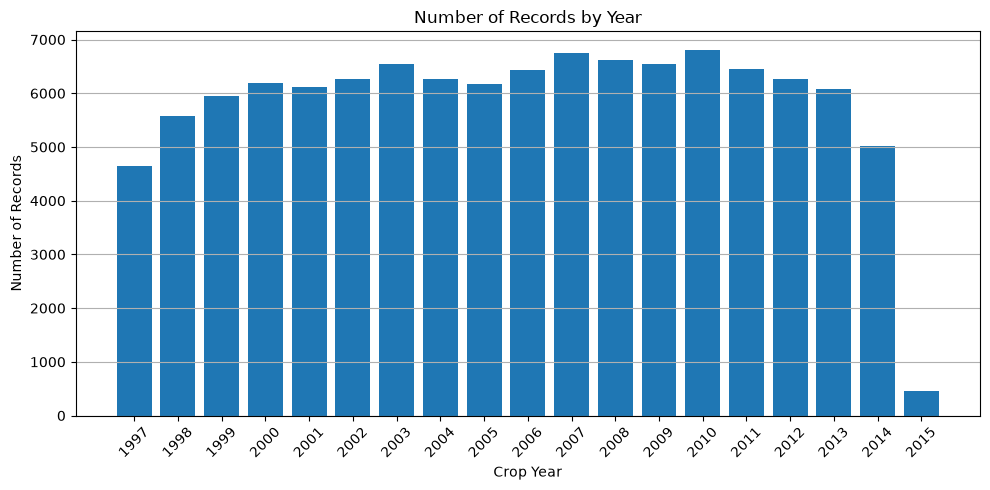

In [6]:
# Plot the number of records by year
plt.figure(figsize=(10, 5))
plt.bar(year_counts.index, year_counts.values)
plt.xlabel("Crop Year")
plt.ylabel("Number of Records")
plt.title("Number of Records by Year")
plt.xticks(year_counts.index, rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

Bản ghi năm 2015 giảm 91,05% so với năm 2014, tức chỉ còn 8,95% số bản ghi của 2014

In [7]:
#Loai nam 2015 vi du lieu qua it
print("Records in 2015:", (df["Crop_Year"] == 2015).sum())
model_data = df[df["Crop_Year"] < 2015].copy()
print("Shape before removing 2015:", df.shape)
print("Shape after removing 2015:", model_data.shape)
print("Year range after filtering:",
      model_data["Crop_Year"].min(),
      "-",
      model_data["Crop_Year"].max())

Records in 2015: 449
Shape before removing 2015: (111207, 10)
Shape after removing 2015: (110758, 10)
Year range after filtering: 1997 - 2014


In [8]:
#Do phu theo bang-cay-mua
availability = (
    df.groupby(["State_Name", "Crop", "Season"])
    .agg(
        Record_Count=("Yield", "size"),
        Year_Count=("Crop_Year", "nunique"),
        District_Count=("District_ID", "nunique"),
        First_Year=("Crop_Year", "min"),
        Last_Year=("Crop_Year", "max")
    ).reset_index()
)
availability.to_csv(OUT2 / "Availability.csv", index=False)
print("\nCác nhóm có ít dữ liệu:")
print( 
    availability.sort_values(
        ["Year_Count", "Record_Count"]
    ).head(20)
)



Các nhóm có ít dữ liệu:
                      State_Name               Crop      Season  Record_Count  \
89                  Chhattisgarh              Maize        Rabi             1   
90                  Chhattisgarh              Maize      Summer             1   
96                  Chhattisgarh          Sugarcane      Kharif             1   
103       Dadra and Nagar Haveli               Gram        Rabi             1   
146                      Haryana               Gram      Kharif             1   
171            Jammu and Kashmir          Arhar/Tur        Rabi             1   
185            Jammu and Kashmir               Urad        Rabi             1   
234                       Kerala              Wheat  Whole Year             1   
279                      Manipur          Arhar/Tur      Kharif             1   
283                      Manipur  Rapeseed &Mustard      Winter             1   
291                      Manipur          Sugarcane        Rabi             1   
528

In [9]:
#1.Tinh thong ke Yield theo tung loai cay
crop_summary = (
    model_data.groupby("Crop")["Yield"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reset_index()
)
# Tinh he so bien thien CV
crop_summary["CV_Percent"] = (
    crop_summary["std"] / crop_summary["mean"]
) * 100
crop_summary = crop_summary.sort_values(
    "mean",
    ascending=False
)
crop_summary.round(3)
crop_summary.to_csv(
    OUT2/ "Top12_Crop_Summary.csv",
    index=False
)
# 2. Summarize yield by state, crop and season
summary = (
    model_data.groupby(["State_Name", "Crop", "Season"])["Yield"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)
summary.to_csv(OUT2 / "Summary_state_crop_season.csv", index=False)

# 3. Summarize yield by state and crop
summary_state_crop = (
    model_data.groupby(["State_Name", "Crop"])["Yield"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

summary_state_crop.to_csv(OUT2 / "Summary_state_crop.csv", index=False)
display(summary_state_crop)
# 4. Count records for each state and year
coverage = pd.crosstab(model_data["State_Name"], model_data["Crop_Year"])

coverage = coverage.reindex(
    columns=range(model_data["Crop_Year"].min(), model_data["Crop_Year"].max() + 1),
    fill_value=0
)
coverage.to_csv(OUT2 / "Coverage.csv", index=False)
display(coverage)
print("Created all 4 CSV files.")

,State_Name,Crop,count,mean,std
0,Andaman and Nicobar Islands,Arhar/Tur,2,0.476111,0.237293
1,Andaman and Nicobar Islands,Groundnut,2,0.960951,0.665569
2,Andaman and Nicobar Islands,Maize,3,3.107475,1.842765
3,Andaman and Nicobar Islands,Moong(Green Gram),3,0.602192,0.128619
4,Andaman and Nicobar Islands,Rice,17,2.904786,0.898786
...,...,...,...,...,...
333,West Bengal,Rice,969,2.429587,0.644281
334,West Bengal,Sesamum,514,0.711096,0.263534
335,West Bengal,Sugarcane,274,83.997411,26.710375
336,West Bengal,Urad,496,0.653074,0.642959


Crop_Year,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
State_Name,,,,,,,,,,,,,,,,,,
Andaman and Nicobar Islands,0,0,0,4,4,4,3,3,3,5,0,0,0,19,0,0,0,0
Andhra Pradesh,194,206,213,238,237,237,231,229,221,226,158,219,235,230,232,226,234,246
Arunachal Pradesh,83,83,46,46,47,53,50,56,53,55,55,54,52,51,51,50,52,52
Assam,227,228,228,227,274,275,275,253,320,322,323,322,324,324,320,320,320,320
Bihar,443,407,516,519,479,522,545,540,535,479,532,525,490,526,487,522,519,507
Chandigarh,0,8,8,7,5,5,3,3,3,3,3,3,3,3,0,0,0,0
Chhattisgarh,0,0,0,213,216,217,215,218,214,213,239,239,226,237,350,351,352,349
Dadra and Nagar Haveli,0,11,9,9,8,8,8,10,11,12,6,6,6,13,13,13,6,6
Goa,6,0,0,0,0,0,0,6,6,6,6,9,9,9,9,8,9,8


Created all 4 CSV files.


Number of crops: 12
Crop
Rice                 15003
Maize                13727
Moong(Green Gram)    10046
Urad                  9646
Sesamum               8770
Groundnut             8711
Wheat                 7862
Sugarcane             7799
Rapeseed &Mustard     7501
Arhar/Tur             7476
Gram                  7227
Jowar                 6990
Name: count, dtype: int64


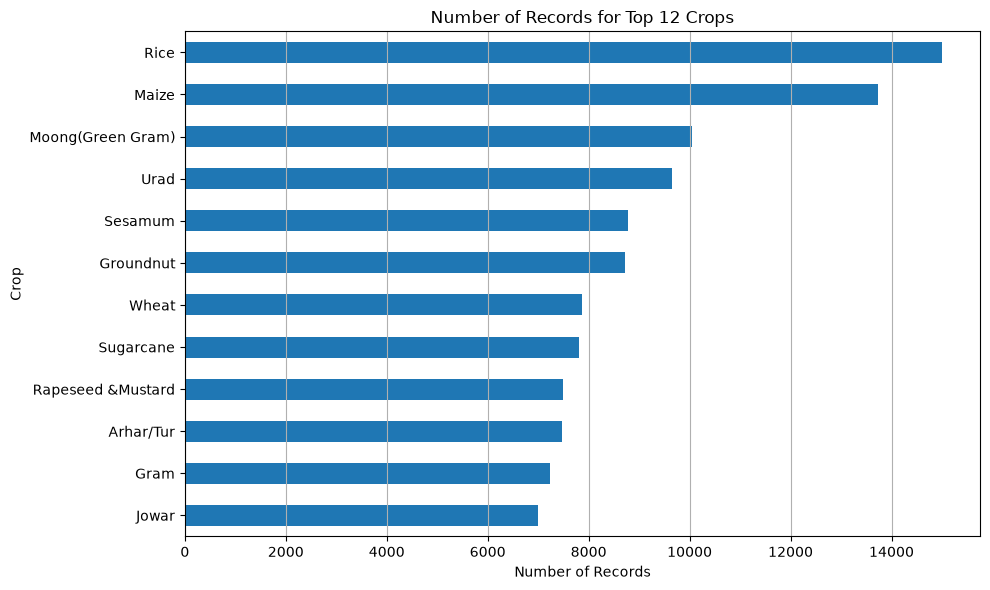

In [10]:
# Count records by crop after filtering
crop_counts = model_data["Crop"].value_counts()

print("Number of crops:", model_data["Crop"].nunique())
print(crop_counts)
# Plot the number of records by crop
plt.figure(figsize=(10, 6))
crop_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of Records")
plt.ylabel("Crop")
plt.title("Number of Records for Top 12 Crops")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

,Crop_Year,Crop,Yield
0,1997,Arhar/Tur,0.634852
1,1997,Gram,0.698460
2,1997,Groundnut,1.082201
3,1997,Jowar,0.916411
4,1997,Maize,12.345493
...,...,...,...
211,2014,Rice,2.365464
212,2014,Sesamum,0.455310
213,2014,Sugarcane,58.405437
214,2014,Urad,0.561310


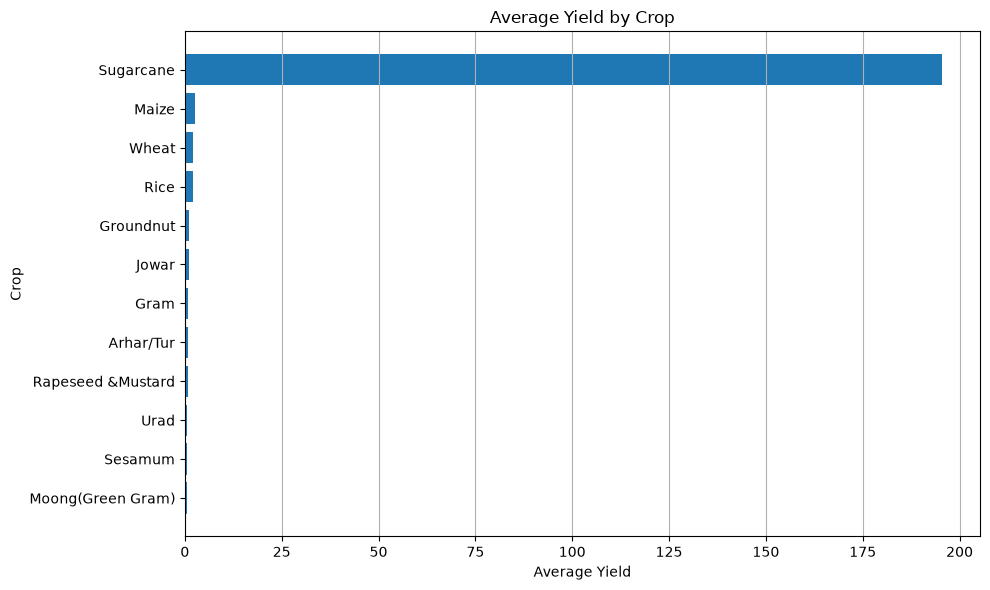

In [11]:
# Calculate average yield by year and crop
yearly_yield = (
    model_data
    .groupby(["Crop_Year", "Crop"])["Yield"]
    .mean()
    .reset_index()
)

display(yearly_yield)
# Plot average yield by crop
plot_data = crop_summary.sort_values("mean")

plt.figure(figsize=(10, 6))
plt.barh(plot_data["Crop"], plot_data["mean"])
plt.xlabel("Average Yield")
plt.ylabel("Crop")
plt.title("Average Yield by Crop")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

Season,Autumn,Kharif,Rabi,Summer,Whole Year,Winter
Crop,,,,,,
Arhar/Tur,0.203,0.801,0.859,0.216,0.776,0.259
Gram,NaN,0.558,0.837,NaN,0.690,0.882
Groundnut,0.862,1.054,1.573,1.449,1.654,1.045
Jowar,0.368,1.003,1.064,1.901,1.047,NaN
Maize,9.323,1.764,3.068,2.268,3.015,1.570
Moong(Green Gram),0.220,0.429,0.447,0.574,0.474,0.259
Rapeseed &Mustard,NaN,0.364,0.811,NaN,0.585,0.198
Rice,1.421,2.040,2.701,2.301,1.931,1.749
Sesamum,0.342,0.379,0.318,1.657,0.538,0.308


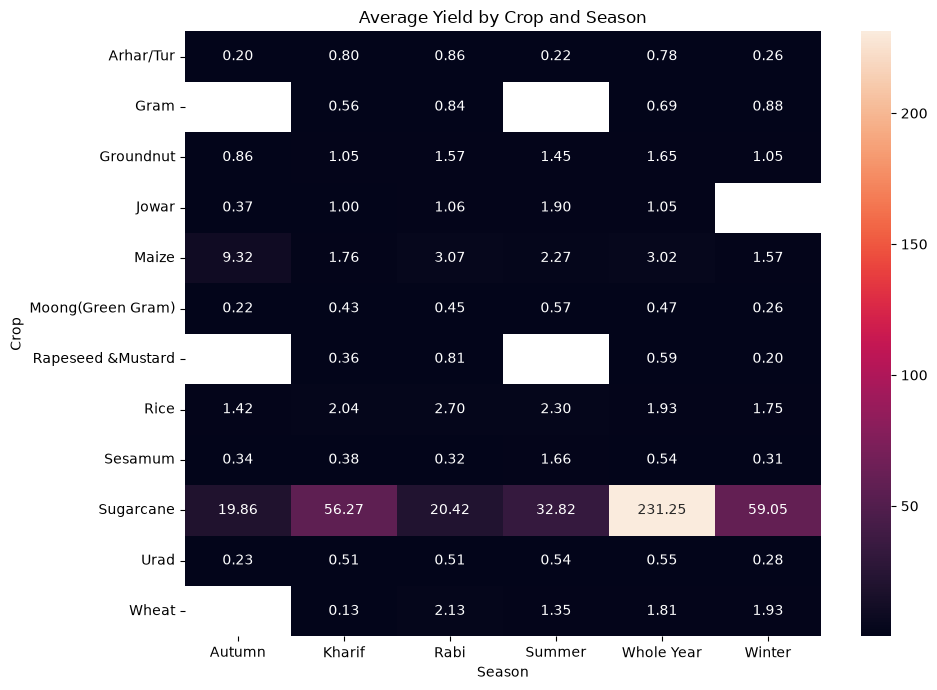

In [12]:
# Calculate average yield by crop and season
crop_season = pd.pivot_table(
    model_data,
    values="Yield",
    index="Crop",
    columns="Season",
    aggfunc="mean"
)

display(crop_season.round(3))
# Plot average yield by crop and season
plt.figure(figsize=(10, 7))
sns.heatmap(
    crop_season,
    annot=True,
    fmt=".2f"
)
plt.title("Average Yield by Crop and Season")
plt.xlabel("Season")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

,Crop,mean,std,CV_Percent
1,Gram,0.830,0.393,47.321
11,Wheat,2.094,1.059,50.566
0,Arhar/Tur,0.797,0.433,54.338
5,Moong(Green Gram),0.453,0.257,56.738
3,Jowar,1.049,0.649,61.892
6,Rapeseed &Mustard,0.772,0.482,62.374
10,Urad,0.495,0.316,63.926
2,Groundnut,1.195,0.806,67.385
7,Rice,1.997,2.053,102.797
8,Sesamum,0.460,2.920,634.387


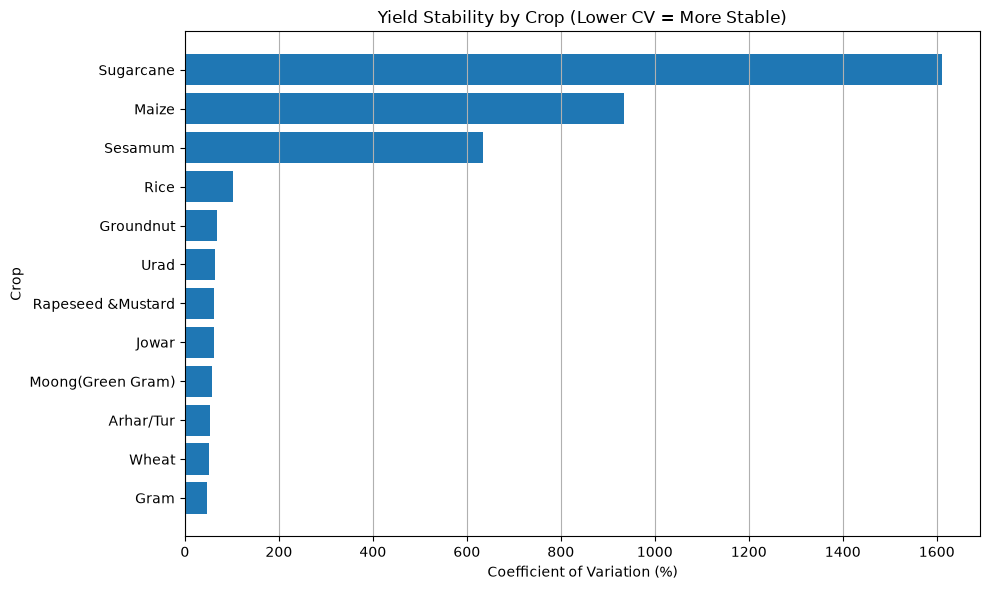

In [13]:
# Compare yield variability using CV
cv_table = crop_summary[
    ["Crop", "mean", "std", "CV_Percent"]
].sort_values("CV_Percent")

display(cv_table.round(3))
# Plot yield variability by crop
plt.figure(figsize=(10, 6))
plt.barh(cv_table["Crop"], cv_table["CV_Percent"])
plt.xlabel("Coefficient of Variation (%)")
plt.ylabel("Crop")
plt.title("Yield Stability by Crop (Lower CV = More Stable)")
plt.grid(axis="x")
plt.tight_layout()
plt.show()

## 2. Diagnostic Analysis

In [14]:
# Cell 5 - Pearson va Spearman theo State-Crop
correlation_rows = []


for (state, crop), group in dev.groupby(
    ["State_Name", "Crop"]
):
    annual = (
        group
        .groupby("Crop_Year")[["Production", "Area"]]
        .sum()
        .reset_index()
    )
    annual["Annual_Yield"] = (
        annual["Production"] /
        annual["Area"].replace(0, np.nan)
    )
    year_count = annual["Crop_Year"].nunique()
    row = {
        "State_Name": state,
        "Crop": crop,
        "Year_Count": year_count,
        "First_Year": annual["Crop_Year"].min(),
        "Last_Year": annual["Crop_Year"].max()
    }

    if (
        year_count >= 5 and
        annual["Annual_Yield"].nunique() > 1
    ):

        pearson_r, pearson_p = pearsonr(
            annual["Crop_Year"],
            annual["Annual_Yield"]
        )

        spearman_rho, spearman_p = spearmanr(
            annual["Crop_Year"],
            annual["Annual_Yield"]
        )

        row.update({
            "Pearson_r": pearson_r,
            "Pearson_p": pearson_p,
            "Spearman_rho": spearman_rho,
            "Spearman_p": spearman_p,
            "Status": "Calculated"
        })

    else:

        row.update({
            "Pearson_r": np.nan,
            "Pearson_p": np.nan,
            "Spearman_rho": np.nan,
            "Spearman_p": np.nan,
            "Status": "Insufficient data"
        })

    correlation_rows.append(row)

correlations = pd.DataFrame(correlation_rows)

correlations["Abs_Pearson_r"] = (
    correlations["Pearson_r"].abs()
)

correlations = correlations.sort_values(
    ["Abs_Pearson_r", "Year_Count"],
    ascending=[False, False]
)

correlations.to_csv(
    OUT2/ "correlations.csv",
    index=False
)

correlations.head(15)

,State_Name,Crop,Year_Count,First_Year,Last_Year,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Status,Abs_Pearson_r
198,Mizoram,Moong(Green Gram),5,2001,2005,0.980052,3.371975e-03,1.000000,1.404265e-24,Calculated,0.980052
296,Tripura,Rice,15,1998,2012,0.949970,6.109682e-08,0.967857,3.596536e-09,Calculated,0.949970
164,Madhya Pradesh,Sesamum,16,1997,2012,0.940628,5.954968e-08,0.947059,2.715731e-08,Calculated,0.940628
290,Tripura,Arhar/Tur,10,1998,2012,0.932960,8.146121e-05,0.951515,2.279855e-05,Calculated,0.932960
115,Himachal Pradesh,Sugarcane,9,1999,2010,0.922707,3.916739e-04,0.850000,3.704777e-03,Calculated,0.922707
332,West Bengal,Rice,16,1997,2012,0.921870,3.868680e-07,0.902941,1.677724e-06,Calculated,0.921870
230,Puducherry,Jowar,8,1999,2012,0.920321,1.190284e-03,0.763763,2.739604e-02,Calculated,0.920321
297,Tripura,Sesamum,10,1998,2012,0.912406,2.314664e-04,0.890909,5.421442e-04,Calculated,0.912406
44,Bihar,Sesamum,15,1997,2012,0.909077,2.684323e-06,0.932143,4.241218e-07,Calculated,0.909077
241,Punjab,Maize,16,1997,2012,0.908863,1.097400e-06,0.902941,1.677724e-06,Calculated,0.908863


In [15]:
#so sanh yield giua hai mua Kharif va Rabi o Karnataka cho cay Bắp
selected = dev[
    (dev["State_Name"] == "Karnataka") &
    (dev["Crop"] == "Maize") &
    (dev["Season"].isin(["Kharif", "Rabi"]))
].copy()

district_year_season = (
    selected
    .groupby(
        ["District_Name", "Crop_Year", "Season"]
    )[["Production", "Area"]]
    .sum()
    .reset_index()
)

district_year_season["Yield"] = (
    district_year_season["Production"] /
    district_year_season["Area"]
)

paired = district_year_season.pivot(
    index=["District_Name", "Crop_Year"],
    columns="Season",
    values="Yield"
)

paired = paired.reindex(
    columns=["Kharif", "Rabi"]
).dropna()

paired["Difference"] = (
    paired["Kharif"] -
    paired["Rabi"]
)

district_difference = (
    paired
    .groupby(level="District_Name")["Difference"]
    .mean()
)

n_districts = len(district_difference)

mean_difference = district_difference.mean()

standard_error = (
    district_difference.std(ddof=1) /
    np.sqrt(n_districts)
)

t_statistic, p_value = ttest_1samp(
    district_difference,
    popmean=0
)

margin = (
    t.ppf(0.975, df=n_districts - 1) *
    standard_error
)

ci_lower = mean_difference - margin
ci_upper = mean_difference + margin

if p_value < 0.05:
    conclusion = "Reject H0: significant difference"
else:
    conclusion = "Fail to reject H0: no significant difference"

paired_test = pd.DataFrame({
    "State_Name": ["Karnataka"],
    "Crop": ["Maize"],
    "Comparison": ["Kharif - Rabi"],
    "District_Count": [n_districts],
    "Matched_District_Year_Pairs": [len(paired)],
    "Mean_Difference": [mean_difference],
    "CI_Lower_95": [ci_lower],
    "CI_Upper_95": [ci_upper],
    "t_statistic": [t_statistic],
    "p_value": [p_value],
    "Conclusion": [conclusion],
    "Limitation": [
        "Observational data; repeated years are averaged within district before testing."
    ]
})

paired_test.to_csv(
    OUT2/ "paired_test.csv",
    index=False
)

paired_test

,State_Name,Crop,Comparison,District_Count,Matched_District_Year_Pairs,Mean_Difference,CI_Lower_95,CI_Upper_95,t_statistic,p_value,Conclusion,Limitation
0,Karnataka,Maize,Kharif - Rabi,27,366,0.161571,-0.062125,0.385266,1.484665,0.149657,Fail to reject H0: no significant difference,Observational data; repeated years are average...


In [16]:
# Cell 7 - Hoi quy xu huong Rice-Kharif tai Karnataka
reg_source = dev[
    (dev["State_Name"] == "Karnataka") &
    (dev["Crop"] == "Rice") &
    (dev["Season"] == "Kharif")
].copy()
required_years = sorted(
    dev["Crop_Year"].unique()
)

district_year_count = (
    reg_source
    .groupby("District_Name")["Crop_Year"]
    .nunique()
)

complete_districts = district_year_count[
    district_year_count == len(required_years)
].index

fixed_panel = reg_source[
    reg_source["District_Name"].isin(
        complete_districts
    )
].copy()

regression_yearly = (
    fixed_panel
    .groupby("Crop_Year")[["Production", "Area"]]
    .sum()
    .reset_index()
)

regression_yearly["Yield"] = (
    regression_yearly["Production"] /
    regression_yearly["Area"]
)

reg = linregress(
    regression_yearly["Crop_Year"],
    regression_yearly["Yield"]
)

r_squared = reg.rvalue ** 2

regression_example = pd.DataFrame({
    "State_Name": ["Karnataka"],
    "Crop": ["Rice"],
    "Season": ["Kharif"],
    "Complete_District_Count": [
        len(complete_districts)
    ],
    "Year_Count": [
        len(regression_yearly)
    ],
    "Slope_per_Year": [reg.slope],
    "Intercept": [reg.intercept],
    "R_Squared": [r_squared],
    "p_value": [reg.pvalue],
    "Slope_Std_Error": [reg.stderr],
    "Limitation": [
        "Historical in-sample trend only; observational data cannot establish causality."
    ]
})

regression_example.to_csv(
    OUT2/ "regression_example.csv",
    index=False
)

regression_example

,State_Name,Crop,Season,Complete_District_Count,Year_Count,Slope_per_Year,Intercept,R_Squared,p_value,Slope_Std_Error,Limitation
0,Karnataka,Rice,Kharif,20,16,0.034042,-65.797326,0.46227,0.003758,0.009813,Historical in-sample trend only; observational...


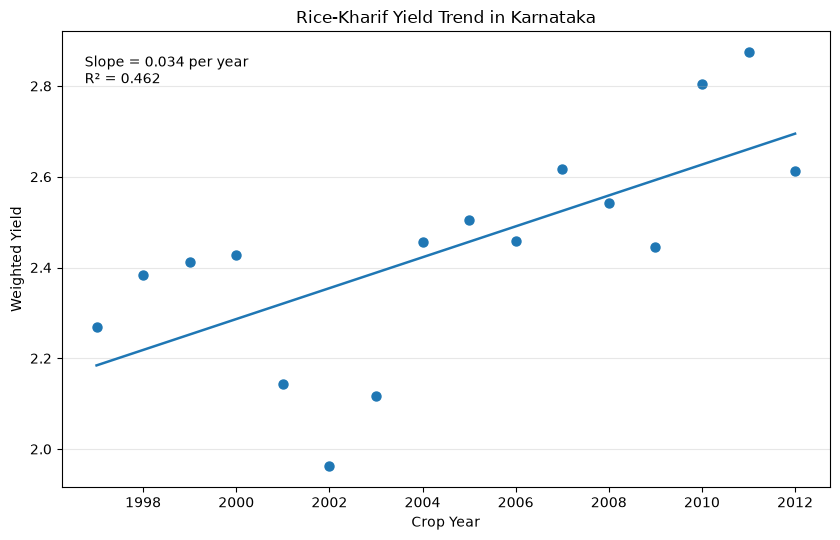

In [17]:
# Cell 8 - 01_regression.png

x = regression_yearly["Crop_Year"]
y = regression_yearly["Yield"]

predicted = (
    reg.intercept +
    reg.slope * x
)

plt.figure(figsize=(8.5, 5.5))

plt.scatter(
    x,
    y,
    s=42
)

plt.plot(
    x,
    predicted,
    linewidth=1.8
)

plt.xlabel("Crop Year")
plt.ylabel("Weighted Yield")
plt.title("Rice-Kharif Yield Trend in Karnataka")

plt.text(
    0.03,
    0.95,
    f"Slope = {reg.slope:.3f} per year\nR² = {r_squared:.3f}",
    transform=plt.gca().transAxes,
    va="top",
    fontsize=10
)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(FIG / "01_regression.png", dpi=180, bbox_inches="tight")

plt.show()

In [18]:
# Cell 9 - Chuan bi annual weighted yield

annual_crop = (
    model_data
    .groupby(
        ["Crop", "Crop_Year"]
    )[["Production", "Area"]]
    .sum()
    .reset_index()
)

annual_crop["Yield"] = (
    annual_crop["Production"] /
    annual_crop["Area"]
)

crop_summary = (
    annual_crop
    .groupby("Crop")["Yield"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        min="min",
        max="max"
    )
    .reset_index()
)

crop_summary

,Crop,count,mean,std,min,max
0,Arhar/Tur,18,0.682442,0.103297,0.476033,0.845222
1,Gram,18,0.835131,0.078949,0.717424,1.024189
2,Groundnut,18,1.084903,0.212501,0.693946,1.473907
3,Jowar,18,0.852091,0.091280,0.714673,1.040757
4,Maize,18,2.239694,0.496988,1.679113,3.395558
5,Moong(Green Gram),18,0.383403,0.078635,0.214077,0.511064
6,Rapeseed &Mustard,18,1.041373,0.165882,0.708035,1.373402
7,Rice,18,2.156889,0.215965,1.751517,2.661144
8,Sesamum,18,0.399588,0.073664,0.313707,0.600966
9,Sugarcane,18,72.894244,18.080668,59.929527,143.913560


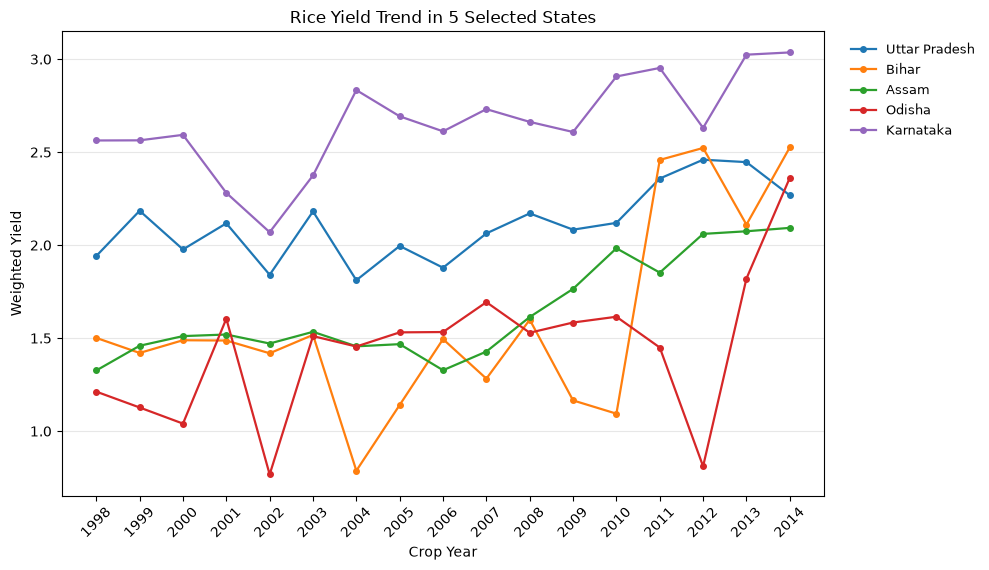

In [19]:
# Cell 10 - 01_line.png
# Rice yield theo nam tai 5 bang co nhieu du lieu Rice nhat

rice = model_data[
    (model_data["Crop"] == "Rice")
    & model_data["Crop_Year"].between(1998, 2014)
].copy()

top_states = (
    rice["State_Name"]
    .value_counts()
    .head(5)
    .index
)

plt.figure(figsize=(10, 5.8))

for state in top_states:

    temp = (
        rice[rice["State_Name"] == state]
        .groupby("Crop_Year")[["Production", "Area"]]
        .sum()
        .reset_index()
    )

    temp["Yield"] = (
        temp["Production"] /
        temp["Area"]
    )

    plt.plot(
        temp["Crop_Year"],
        temp["Yield"],
        marker="o",
        markersize=4,
        linewidth=1.6,
        label=state
    )

plt.xlabel("Crop Year")
plt.ylabel("Weighted Yield")
plt.title("Rice Yield Trend in 5 Selected States")

years = sorted(rice["Crop_Year"].unique())
plt.xticks(years, rotation=45)

plt.grid(axis="y", alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=9
)

plt.tight_layout()

plt.savefig(FIG / "02_line.png", dpi=180, bbox_inches="tight")

plt.show()

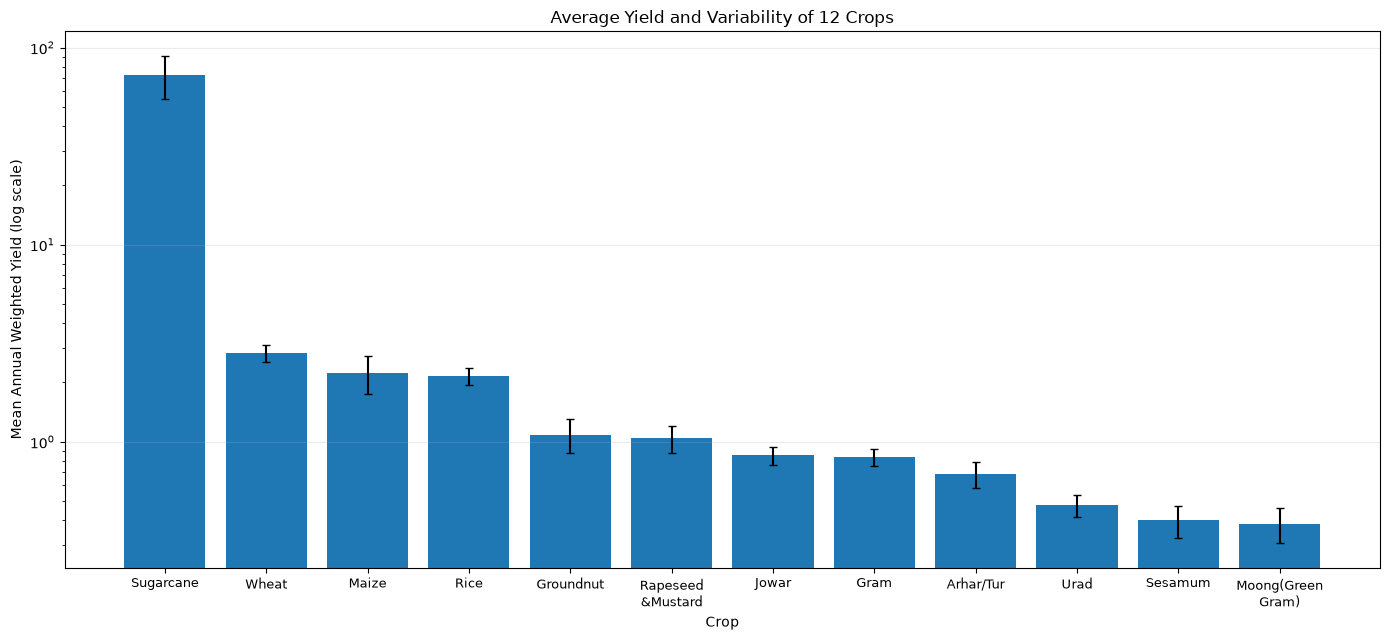

In [20]:
# Cell 11 - 02_bar.png
# So sanh mean va SD cua 12 crops bang bieu do cot dung
# Ten crop duoc xuong dong de de doc, khong xoay nghieng

bar_data = crop_summary.sort_values(
    "mean",
    ascending=False
)

bar_labels = [
    "\n".join(textwrap.wrap(str(crop), width=12))
    for crop in bar_data["Crop"]
]

plt.figure(figsize=(14, 6.5))

plt.bar(
    range(len(bar_data)),
    bar_data["mean"],
    yerr=bar_data["std"],
    capsize=3
)

plt.yscale("log")

plt.xlabel("Crop")
plt.ylabel("Mean Annual Weighted Yield (log scale)")
plt.title("Average Yield and Variability of 12 Crops")

plt.xticks(
    range(len(bar_data)),
    bar_labels,
    rotation=0,
    ha="center",
    fontsize=9
)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(FIG / "03_bar.png", dpi=180, bbox_inches="tight")

plt.show()

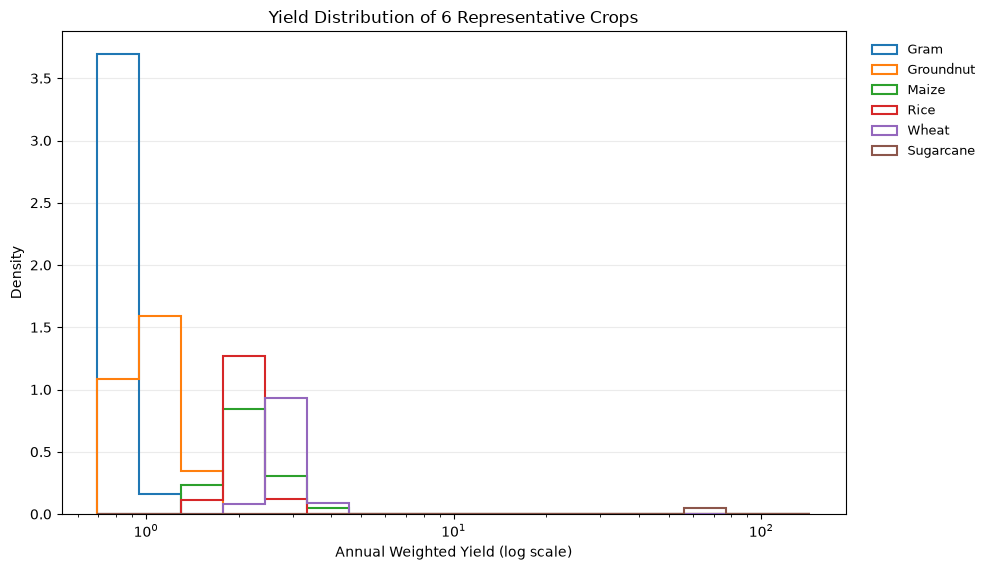

In [21]:
# Cell 12 - 03_histogram.png
# Phan phoi Yield cua 6 crops dai dien de bieu do de doc hon

representative_crops = [
    "Gram",
    "Groundnut",
    "Maize",
    "Rice",
    "Wheat",
    "Sugarcane"
]

hist_data = annual_crop[
    annual_crop["Crop"].isin(
        representative_crops
    )
].copy()

positive_yield = hist_data[
    hist_data["Yield"] > 0
]["Yield"]

bins = np.logspace(
    np.log10(positive_yield.min()),
    np.log10(positive_yield.max()),
    18
)

plt.figure(figsize=(10, 5.8))

for crop in representative_crops:

    values = hist_data[
        (hist_data["Crop"] == crop) &
        (hist_data["Yield"] > 0)
    ]["Yield"]

    plt.hist(
        values,
        bins=bins,
        histtype="step",
        density=True,
        linewidth=1.5,
        label=crop
    )

plt.xscale("log")

plt.xlabel("Annual Weighted Yield (log scale)")
plt.ylabel("Density")
plt.title("Yield Distribution of 6 Representative Crops")

plt.grid(axis="y", alpha=0.25)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=9
)

plt.tight_layout()

plt.savefig(FIG / "04_histogram.png", dpi=180, bbox_inches="tight")

plt.show()

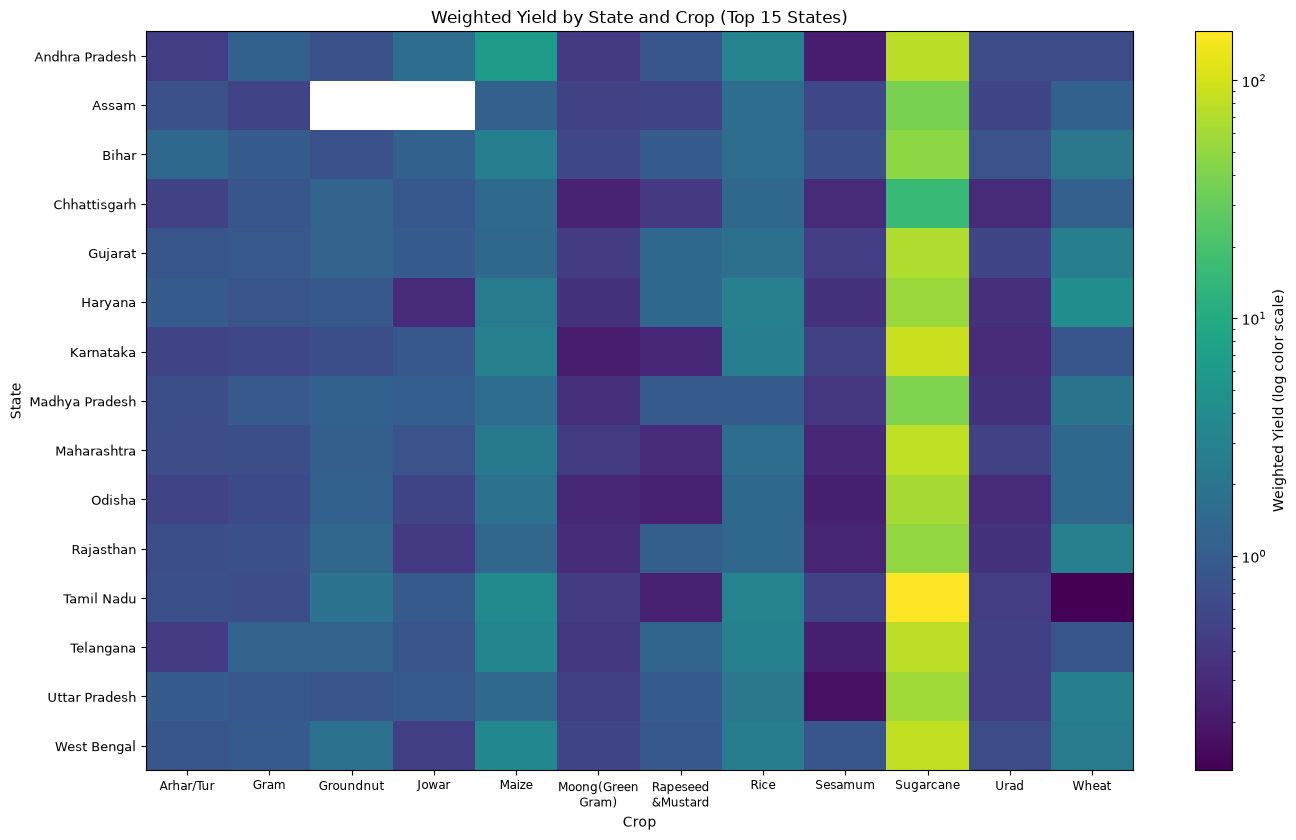

In [22]:
# Cell 13 - 04_heatmap.png
# Heatmap cua 15 bang co nhieu ban ghi nhat
# Ten crop viet thang va xuong dong de de doc

top_heat_states = (
    model_data["State_Name"]
    .value_counts()
    .head(15)
    .index
)

heat_source = model_data[
    model_data["State_Name"].isin(
        top_heat_states
    )
].copy()

state_crop = (
    heat_source
    .groupby(
        ["State_Name", "Crop"]
    )[["Production", "Area"]]
    .sum()
    .reset_index()
)

state_crop["Yield"] = (
    state_crop["Production"] /
    state_crop["Area"]
)

heatmap_data = state_crop.pivot(
    index="State_Name",
    columns="Crop",
    values="Yield"
)

matrix = heatmap_data.values

positive_values = matrix[
    np.isfinite(matrix) &
    (matrix > 0)
]

crop_labels = [
    "\n".join(textwrap.wrap(str(crop), width=12))
    for crop in heatmap_data.columns
]

plt.figure(figsize=(14, 8.5))

image = plt.imshow(
    matrix,
    aspect="auto",
    norm=LogNorm(
        vmin=positive_values.min(),
        vmax=positive_values.max()
    )
)

plt.colorbar(
    image,
    label="Weighted Yield (log color scale)"
)

plt.xticks(
    range(len(heatmap_data.columns)),
    crop_labels,
    rotation=0,
    ha="center",
    fontsize=8.5
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index,
    fontsize=9
)

plt.xlabel("Crop")
plt.ylabel("State")
plt.title("Weighted Yield by State and Crop (Top 15 States)")

plt.tight_layout()

plt.savefig(FIG / "05_heatmap.png", dpi=180, bbox_inches="tight")

plt.show()

C:\Users\PHUONG NHI\AppData\Local\Temp\ipykernel_24508\2062300358.py:59: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(
C:\Users\PHUONG NHI\AppData\Local\Temp\ipykernel_24508\2062300358.py:72: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


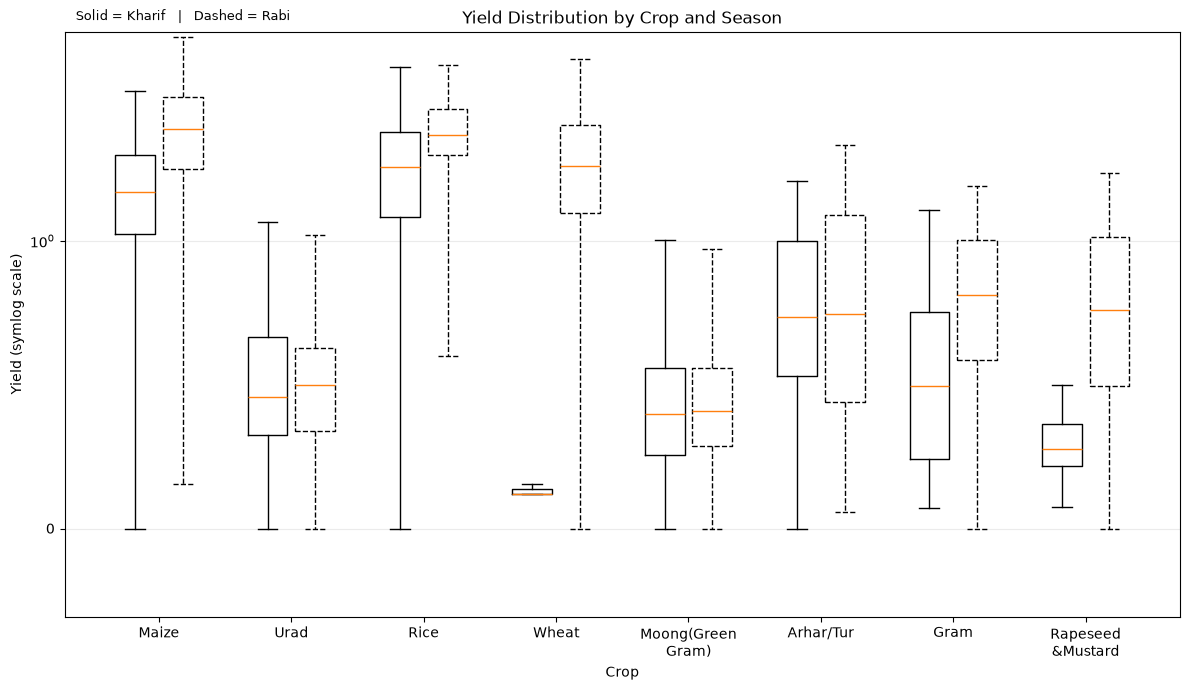

In [23]:
# Cell 14 - 05_boxplot.png
# Boxplot dung cua 8 crops co nhieu du lieu nhat
# Solid = Kharif, Dashed = Rabi

box_source = model_data[
    model_data["Season"].isin(
        ["Kharif", "Rabi"]
    )
].copy()

# Chi lay nhung crop co du ca Kharif va Rabi
season_count = pd.crosstab(
    box_source["Crop"],
    box_source["Season"]
)

valid_crops = season_count[
    (season_count["Kharif"] > 0) &
    (season_count["Rabi"] > 0)
].index

top_box_crops = (
    box_source[
        box_source["Crop"].isin(valid_crops)
    ]["Crop"]
    .value_counts()
    .head(8)
    .index
    .tolist()
)

centers = np.arange(
    1,
    len(top_box_crops) + 1
)

kharif_data = []
rabi_data = []

for crop in top_box_crops:

    kharif_data.append(
        box_source[
            (box_source["Crop"] == crop) &
            (box_source["Season"] == "Kharif")
        ]["Yield"].dropna()
    )

    rabi_data.append(
        box_source[
            (box_source["Crop"] == crop) &
            (box_source["Season"] == "Rabi")
        ]["Yield"].dropna()
    )

plt.figure(figsize=(12, 7))

# Kharif
plt.boxplot(
    kharif_data,
    positions=centers - 0.18,
    vert=True,
    widths=0.30,
    showfliers=False,
    manage_ticks=False,
    boxprops=dict(linestyle="-"),
    whiskerprops=dict(linestyle="-"),
    capprops=dict(linestyle="-")
)

# Rabi
plt.boxplot(
    rabi_data,
    positions=centers + 0.18,
    vert=True,
    widths=0.30,
    showfliers=False,
    manage_ticks=False,
    boxprops=dict(linestyle="--"),
    whiskerprops=dict(linestyle="--"),
    capprops=dict(linestyle="--")
)

# Ten crop xuong dong neu dai
box_labels = [
    "\n".join(
        textwrap.wrap(
            str(crop),
            width=14
        )
    )
    for crop in top_box_crops
]

plt.xticks(
    centers,
    box_labels,
    rotation=0,
    ha="center"
)

plt.yscale(
    "symlog",
    linthresh=1
)

plt.xlabel("Crop")
plt.ylabel("Yield (symlog scale)")
plt.title("Yield Distribution by Crop and Season")

plt.text(
    0.01,
    1.02,
    "Solid = Kharif   |   Dashed = Rabi",
    transform=plt.gca().transAxes,
    fontsize=9
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(FIG / "06_boxplot.png", dpi=180, bbox_inches="tight")

plt.show()

In [24]:
# Cell 15 - Tao figure_notes_analysis.csv

line_results = []

for state in top_states:

    temp = (
        rice[rice["State_Name"] == state]
        .groupby("Crop_Year")[["Production", "Area"]]
        .sum()
        .reset_index()
    )

    temp["Yield"] = (
        temp["Production"] /
        temp["Area"]
    )

    line_reg = linregress(
        temp["Crop_Year"],
        temp["Yield"]
    )

    line_results.append({
        "State_Name": state,
        "Slope": line_reg.slope
    })

line_table = pd.DataFrame(
    line_results
)

largest_slope_state = (
    line_table
    .sort_values(
        "Slope",
        ascending=False
    )
    .iloc[0]["State_Name"]
)

highest_crop = (
    crop_summary
    .sort_values(
        "mean",
        ascending=False
    )
    .iloc[0]["Crop"]
)

top_state_crop = (
    state_crop
    .sort_values(
        "Yield",
        ascending=False
    )
    .iloc[0]
)

figure_notes = pd.DataFrame([
    {
        "File": "01_line.png",
        "Chart": "Line chart",
        "Purpose": "Theo doi xu huong nang suat Rice theo nam tai 5 bang co nhieu du lieu Rice nhat.",
        "Main_Finding": f"{largest_slope_state} co slope tang lon nhat trong 5 bang duoc hien thi.",
        "Limitation": "Chi hien thi 5 bang de bieu do de doc."
    },
    {
        "File": "02_bar.png",
        "Chart": "Bar chart with SD",
        "Purpose": "So sanh mean va SD cua annual weighted yield giua 12 crops.",
        "Main_Finding": f"{highest_crop} co mean annual weighted yield cao nhat.",
        "Limitation": "Dung log scale vi cac crop co thang Yield rat khac nhau; ten crop duoc xuong dong de de doc."
    },
    {
        "File": "03_histogram.png",
        "Chart": "Histogram",
        "Purpose": "Xem phan phoi Yield cua 6 crops dai dien.",
        "Main_Finding": "Phan phoi Yield khac nhau ro giua cac crop dai dien.",
        "Limitation": "Chi hien thi 6 crops dai dien de bieu do khong qua roi."
    },
    {
        "File": "04_heatmap.png",
        "Chart": "Heatmap",
        "Purpose": "So sanh weighted yield theo State-Crop.",
        "Main_Finding": f"Trong 15 bang hien thi, gia tri weighted yield lon nhat la {top_state_crop['State_Name']} - {top_state_crop['Crop']}.",
        "Limitation": "Chi hien thi 15 bang co nhieu ban ghi nhat; dung log color scale; ten crop viet thang va xuong dong de de doc."
    },
    {
        "File": "05_boxplot.png",
        "Chart": "Boxplot",
        "Purpose": "So sanh phan phoi Yield giua Kharif va Rabi theo crop.",
        "Main_Finding": "Do phan tan Yield khac nhau theo ca crop va season.",
        "Limitation": "Chi hien thi 8 crops co nhieu du lieu nhat; outlier chi an tren hinh, khong xoa khoi data."
    },
    {
        "File": "06_regression.png",
        "Chart": "Scatter + regression line",
        "Purpose": "Phan tich xu huong Rice-Kharif tai Karnataka tren cung nhom huyen.",
        "Main_Finding": f"Slope = {reg.slope:.4f}, R2 = {r_squared:.3f}.",
        "Limitation": "Chi la xu huong lich su trong mau; khong chung minh nhan qua."
    }
])

figure_notes.to_csv(
    OUT2/ "figure_notes_analysis.csv",
    index=False
)

figure_notes

,File,Chart,Purpose,Main_Finding,Limitation
0,01_line.png,Line chart,Theo doi xu huong nang suat Rice theo nam tai ...,Bihar co slope tang lon nhat trong 5 bang duoc...,Chi hien thi 5 bang de bieu do de doc.
1,02_bar.png,Bar chart with SD,So sanh mean va SD cua annual weighted yield g...,Sugarcane co mean annual weighted yield cao nhat.,Dung log scale vi cac crop co thang Yield rat ...
2,03_histogram.png,Histogram,Xem phan phoi Yield cua 6 crops dai dien.,Phan phoi Yield khac nhau ro giua cac crop dai...,Chi hien thi 6 crops dai dien de bieu do khong...
3,04_heatmap.png,Heatmap,So sanh weighted yield theo State-Crop.,"Trong 15 bang hien thi, gia tri weighted yield...",Chi hien thi 15 bang co nhieu ban ghi nhat; du...
4,05_boxplot.png,Boxplot,So sanh phan phoi Yield giua Kharif va Rabi th...,Do phan tan Yield khac nhau theo ca crop va se...,Chi hien thi 8 crops co nhieu du lieu nhat; ou...
5,06_regression.png,Scatter + regression line,Phan tich xu huong Rice-Kharif tai Karnataka t...,"Slope = 0.0340, R2 = 0.462.",Chi la xu huong lich su trong mau; khong chung...


## 3. Data Preparation for Modeling

In [25]:

MODEL_STATES = [
    "Uttar Pradesh",
    "Madhya Pradesh",
    "Maharashtra",
    "Rajasthan",
    "Karnataka",
    "Bihar",
    "West Bengal",
    "Tamil Nadu"
]
prediction_data = model_data[
    model_data["State_Name"].isin(MODEL_STATES)
].copy()

# Tạo biến năm cho mô hình.
prediction_data["Year_Index"] = (
    prediction_data["Crop_Year"] - 1998
)

# Các cột giữ lại trong file bàn giao.
keep_cols = [
    "State_Name",
    "District_Name",
    "District_ID",
    "Crop_Year",
    "Year_Index",
    "Season",
    "Crop",
    "Area",
    "Production",
    "Yield",
    "Outlier_Flag"
]

model_ready = prediction_data[keep_cols].copy()

# Các biến thực sự đưa vào mô hình.
feature_cols = [
    "Year_Index",
    "State_Name",
    "District_ID",
    "Crop",
    "Season"
]

target_col = "Yield"

print("Dữ liệu mô tả:")
print("Số bang:", model_data["State_Name"].nunique())
print("Số cây:", model_data["Crop"].nunique())
print("Số dòng:", len(model_data))

print("\nDữ liệu dành cho mô hình:")
print("Số bang:", model_ready["State_Name"].nunique())
print("Số cây:", model_ready["Crop"].nunique())
print("Số dòng:", len(model_ready))

display(model_ready["State_Name"].value_counts())
display(model_ready["Crop"].value_counts())
display(model_ready.head())

Dữ liệu mô tả:
Số bang: 33
Số cây: 12
Số dòng: 110758

Dữ liệu dành cho mô hình:
Số bang: 8
Số cây: 12
Số dòng: 65498


State_Name
Uttar Pradesh     17277
Madhya Pradesh     9241
Bihar              9093
Karnataka          7903
Maharashtra        7657
West Bengal        5037
Rajasthan          4783
Tamil Nadu         4507
Name: count, dtype: int64

Crop
Maize                8989
Rice                 7571
Moong(Green Gram)    6142
Urad                 5689
Groundnut            5158
Jowar                5063
Sesamum              4753
Gram                 4554
Sugarcane            4516
Arhar/Tur            4508
Wheat                4325
Rapeseed &Mustard    4230
Name: count, dtype: int64

,State_Name,District_Name,District_ID,Crop_Year,Year_Index,Season,Crop,Area,Production,Yield,Outlier_Flag
10248,Bihar,ARARIA,Bihar / ARARIA,1997,-1,Autumn,Rice,17876.0,21397.0,1.196968,False
10249,Bihar,ARARIA,Bihar / ARARIA,1997,-1,Kharif,Arhar/Tur,354.0,426.0,1.203390,False
10250,Bihar,ARARIA,Bihar / ARARIA,1997,-1,Kharif,Groundnut,8.0,10.0,1.250000,False
10251,Bihar,ARARIA,Bihar / ARARIA,1997,-1,Kharif,Maize,3919.0,8691.0,2.217658,False
10252,Bihar,ARARIA,Bihar / ARARIA,1997,-1,Kharif,Sesamum,4.0,2.0,0.500000,False


In [26]:
#Chia Train / Validation / Test
train_data = model_ready[
    model_ready["Crop_Year"] <= 2010
].copy()
validation_data = model_ready[
    model_ready["Crop_Year"].between(2011, 2012)
].copy()
test_data = model_ready[
    model_ready["Crop_Year"].between(2013, 2014)
].copy()
print("Train shape:", train_data.shape)
print("Train years:",
      train_data["Crop_Year"].min(),
      "-",
      train_data["Crop_Year"].max())
print("\nValidation shape:", validation_data.shape)
print("Validation years:",
      validation_data["Crop_Year"].min(),
      "-",
      validation_data["Crop_Year"].max())
print("\nTest shape:", test_data.shape)
print("Test years:",
      test_data["Crop_Year"].min(),
      "-",
      test_data["Crop_Year"].max())

Train shape: (51561, 11)
Train years: 1997 - 2010

Validation shape: (7426, 11)
Validation years: 2011 - 2012

Test shape: (6511, 11)
Test years: 2013 - 2014


In [27]:
#Kiem tra moi tap van co du 12 cay

split_check = pd.DataFrame({
    "Train": train_data["Crop"].value_counts(),
    "Validation": validation_data["Crop"].value_counts(),
    "Test": test_data["Crop"].value_counts()
}).fillna(0).astype(int)

print("Number of crops in Train:", train_data["Crop"].nunique())
print("Number of crops in Validation:", validation_data["Crop"].nunique())
print("Number of crops in Test:", test_data["Crop"].nunique())

split_check

Number of crops in Train: 12
Number of crops in Validation: 12
Number of crops in Test: 12


,Train,Validation,Test
Crop,,,
Arhar/Tur,3552,518,438
Gram,3681,472,401
Groundnut,4044,613,501
Jowar,4106,506,451
Maize,6804,1118,1067
Moong(Green Gram),4624,802,716
Rapeseed &Mustard,3451,434,345
Rice,5969,848,754
Sesamum,3872,484,397


In [28]:
# Dữ liệu toàn bộ bang phục vụ phần phân tích.
model_data.to_csv(
    OUT2 / "final_data.csv",
    index=False
)

# Dữ liệu 8 bang phục vụ mô hình.
model_ready.to_csv(
    OUT2 / "model_data_8_states.csv",
    index=False
)

# Ba tập bàn giao trực tiếp trong outputs.
train_data.to_csv(
    OUT / "train.csv",
    index=False
)

validation_data.to_csv(
    OUT / "validation.csv",
    index=False
)

test_data.to_csv(
    OUT / "test.csv",
    index=False
)

# Bảng mô tả toàn bộ bang.
crop_season.to_csv(
    OUT2 / "Top12_Crop_Season_Pivot.csv"
)

# Lưu riêng phạm vi mô hình, giữ nguyên config["states"].
config["model_states"] = MODEL_STATES

(OUT / "config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Đã xuất dữ liệu mô hình cho 8 bang.")

Đã xuất dữ liệu mô hình cho 8 bang.
